# Critère de Kelly en temps continu — version desk

**Objectif** : de l'introduction pédagogique au **dimensionnement de positions** utilisable sur un desk : dérivation corrigée, vérifications numériques, Kelly fractionnaire et **risque de drawdown**, **erreur d'estimation** (le vrai problème pratique), allocation multi-actifs sous contraintes, et backtests avec coûts / financement / sans look-ahead.

| Bloc | Contenu |
|---|---|
| 1 | Dérivation (discret → continu → multi-actifs) et vérification par simulation |
| 2 | Queues épaisses : Kelly gaussien vs Kelly empirique ; Kelly d'un système de trades |
| 3 | Kelly fractionnaire, probabilité de drawdown (formule exacte + Monte-Carlo) |
| 4 | **Erreur d'estimation** : pourquoi le Kelly « plug-in » sur-parie, shrinkage bayésien |
| 5 | Backtest mono-actif (S&P 500) : estimateurs, plafonds de levier, coûts |
| 6 | Portefeuille de 15 actions : Kelly contraint, corrélé vs décorrélé, benchmarks |
| 7 | Comparaison avec le vol-targeting, règles de desk, export JSON |

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from quantdesk import kelly as K
from quantdesk.data import load_prices, to_returns
from quantdesk.style import apply_terminal_style, AMBER, CYAN, GREEN, RED, GREY, VIOLET
apply_terminal_style()
pd.options.display.float_format = "{:,.4f}".format

RF_ANN = 0.02
STOCKS = ["AAPL", "MSFT", "AMZN", "JPM", "XOM", "JNJ", "PG", "KO", "PEP", "WMT", "CVX", "MRK", "HD", "INTC", "IBM"]

if os.path.exists("sp500.csv") and os.path.exists("stocks.csv"):            # fichiers de l'analyse d'origine, si présents
    sp_px = pd.read_csv("sp500.csv", index_col="date", sep=";", parse_dates=True)["sp500"]
    stk_px = pd.read_csv("stocks.csv", index_col="date", sep=";", parse_dates=True)
    SOURCE = "csv locaux"
else:
    pxs, meta = load_prices(["^GSPC"] + STOCKS, start="2000-01-01", cache_dir="data_cache")
    sp_px, stk_px, SOURCE = pxs["^GSPC"], pxs[STOCKS], meta["source"]
r_sp, R_stk = to_returns(sp_px).dropna(), to_returns(stk_px).dropna()
print(f"Source : {SOURCE.upper()} | S&P 500 : {r_sp.index[0].date()} → {r_sp.index[-1].date()} ({len(r_sp)} j) | panier : {R_stk.shape[1]} actions")
if SOURCE == "synthetic":
    print("⚠️  DONNÉES SYNTHÉTIQUES : les chiffres illustrent la mécanique et valident le code ; ne pas en tirer de conclusion de marché.")

Source : SYNTHETIC | S&P 500 : 2000-01-04 → 2026-09-18 (6969 j) | panier : 15 actions
⚠️  DONNÉES SYNTHÉTIQUES : les chiffres illustrent la mécanique et valident le code ; ne pas en tirer de conclusion de marché.


## 1. Dérivation

**Discret.** Pari binaire : gain $b$ par unité misée avec probabilité $p$, perte de $a$ sinon. La croissance log-espérée de la richesse pour une fraction $f$ est $g(f)=p\ln(1+bf)+(1-p)\ln(1-af)$, maximale en $f^*=\frac{p}{a}-\frac{1-p}{b}$ (pour $a=1$ : $f^*=\frac{bp-(1-p)}{b}$).

**Continu (Thorp).** Rendement par période de moyenne $m$ et variance $s^2$, taux sans risque $r$, allocation $f$ dans l'actif risqué :
$$\frac{V(f)}{V_0}=1+r+f\,(X-r).$$
Découpons l'horizon en $n$ pas i.i.d. de moyenne $m/n$ et de variance $s^2/n$ ($X_i=\frac mn+\frac{s}{\sqrt n}U_i$, $U_i=\pm1$, $E[U]=0$, $E[U^2]=1$). Le développement correct de $\ln(1+z)$ est
$$\ln(1+z)=z-\frac{z^2}{2}+\frac{z^3}{3}-\dots$$
avec $z=\frac rn+f\!\left(\frac{m-r}{n}+\frac{s\,U}{\sqrt n}\right)$, donc $E[z]=\frac{r+f(m-r)}{n}$ et $E[z^2]=\frac{f^2s^2}{n}+O(n^{-2})$. En sommant $n$ pas :
$$\boxed{\,g(f)=r+f\,(m-r)-\tfrac12 f^2 s^2\,}\qquad\Rightarrow\qquad \boxed{\,f^*=\frac{m-r}{s^2}\,},\quad g(f^*)=r+\frac{(m-r)^2}{2s^2}=r+\tfrac12 SR^2 .$$

Trois conséquences opérationnelles : (i) $g$ est une parabole **concave** ; (ii) elle est symétrique autour de $f^*$ : parier $2f^*$ ramène la croissance à $r$, au-delà elle passe **sous le taux sans risque** ; (iii) $f^*$ est le **Sharpe divisé par la volatilité**, pas le Sharpe seul.

**Multi-actifs.** $g(F)=r+F^\top(M-r\mathbf 1)-\frac12F^\top\Sigma F\Rightarrow F^*=\Sigma^{-1}(M-r\mathbf 1)$ ; la part $1-\mathbf 1^\top F$ est le cash (ou l'emprunt) au taux $r$. Avec des actifs **non corrélés** on retrouve $f_i^*=\frac{m_i-r}{s_i^2}$.

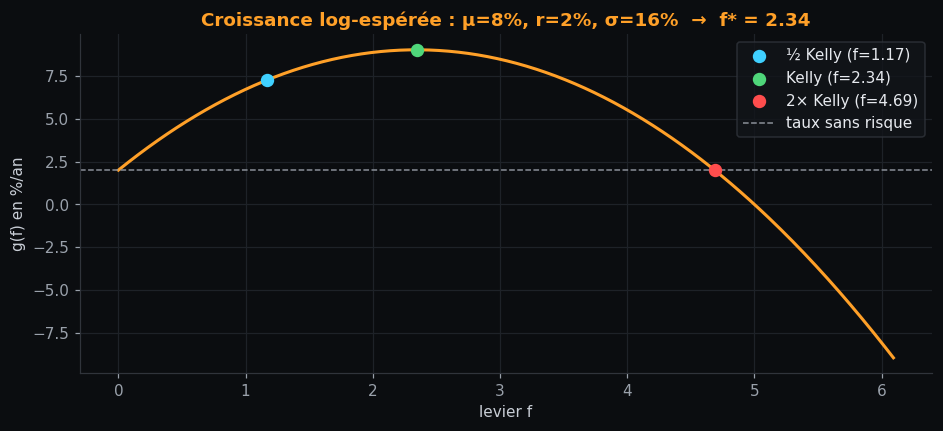

En excès du taux sans risque, ½ Kelly capture 75% de la croissance de Kelly plein (formule : 1−(1−c)² = 75 % pour c = ½).


In [2]:
mu, r, sig = 0.08, 0.02, 0.16
f_star = K.kelly_continuous(mu, sig**2, r)
fs = np.linspace(0, 2.6*f_star, 400)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(fs, K.growth_rate(fs, mu, sig**2, r)*100, color=AMBER, lw=2)
for c, col, lab in [(0.5, CYAN, "½ Kelly"), (1, GREEN, "Kelly"), (2, RED, "2× Kelly")]:
    ax.scatter(c*f_star, K.growth_rate(c*f_star, mu, sig**2, r)*100, color=col, s=60, zorder=5, label=f"{lab} (f={c*f_star:.2f})")
ax.axhline(r*100, color=GREY, ls="--", lw=1, label="taux sans risque"); ax.set_xlabel("levier f"); ax.set_ylabel("g(f) en %/an")
ax.set_title(f"Croissance log-espérée : μ={mu:.0%}, r={r:.0%}, σ={sig:.0%}  →  f* = {f_star:.2f}"); ax.legend(); plt.show()
print(f"En excès du taux sans risque, ½ Kelly capture {(K.growth_rate(.5*f_star,mu,sig**2,r)-r)/(K.growth_rate(f_star,mu,sig**2,r)-r):.0%} de la croissance de Kelly plein "
      f"(formule : 1−(1−c)² = 75 % pour c = ½).")

In [3]:
# Vérification numérique par simulation (rebalancement quotidien, 20 ans × 400 trajectoires)
rng = np.random.default_rng(0); dt = 1/252; T, N = 20*252, 200
z = rng.standard_normal((N, T)); z = np.concatenate([z, -z])          # variables antithétiques : moyenne exactement nulle
Rd = np.exp((mu - .5*sig**2)*dt + sig*np.sqrt(dt)*z) - 1
rows = []
for c in [0, .25, .5, 1, 1.5, 2, 2.5]:
    f = c*f_star
    g_mc = np.log(np.maximum(1 + r*dt + f*(Rd - r*dt), 1e-12)).mean()*252
    rows.append({"c = f/f*": c, "f": f, "g simulée": g_mc, "g théorique": float(K.growth_rate(f, mu, sig**2, r))})
chk = pd.DataFrame(rows).set_index("c = f/f*"); chk["écart"] = chk["g simulée"] - chk["g théorique"]
display(chk)

,f,g simulée,g théorique,écart
c = f/f*,,,,
0.0000,0.0000,0.0200,0.0200,-0.0000
0.2500,0.5859,0.0508,0.0508,0.0000
0.5000,1.1719,0.0727,0.0727,-0.0000
1.0000,2.3438,0.0903,0.0903,-0.0001
1.5000,3.5156,0.0725,0.0727,-0.0002
2.0000,4.6875,0.0194,0.0200,-0.0006
2.5000,5.8594,-0.0694,-0.0679,-0.0015


## 2. Queues épaisses et Kelly d'un système de trades

La formule $\mu/\sigma^2$ ne voit que les deux premiers moments. Pour des rendements asymétriques à queues épaisses, on maximise directement $\frac1T\sum_t\ln\!\big(1+r+f(R_t-r)\big)$ (**Kelly empirique**) — un lissage de la queue gauche que la parabole ignore.

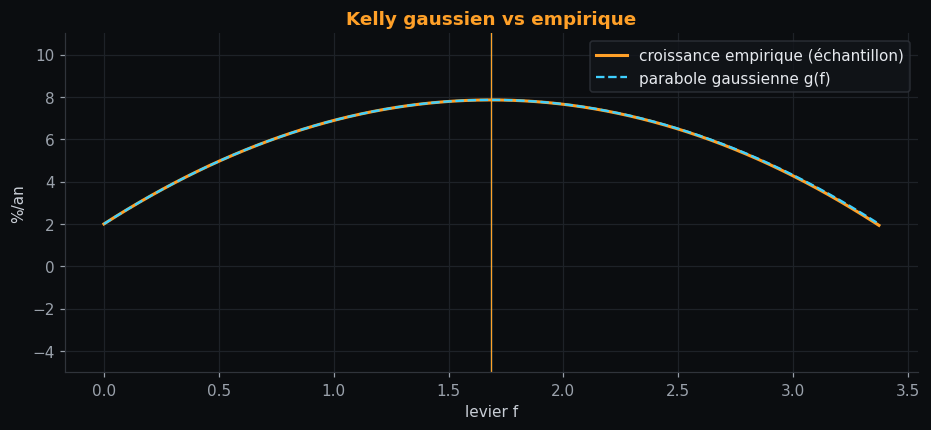

f* gaussien = 1.69 | f* empirique = 1.68 | croissance empirique à f* gaussien = 7.86% vs 7.86% à f* empirique


In [4]:
rf_d = RF_ANN/252
f_gauss = K.kelly_continuous(r_sp.mean(), r_sp.var(), rf_d)
f_emp = K.kelly_empirical(r_sp, rf_d)
grid = np.linspace(0, max(f_gauss, f_emp)*2, 200)
g_emp = [np.mean(np.log1p(rf_d + f*(r_sp - rf_d)))*252 for f in grid]
g_par = K.growth_rate(grid, r_sp.mean()*252, r_sp.var()*252, RF_ANN)
plt.figure(figsize=(10, 4)); plt.plot(grid, np.array(g_emp)*100, color=AMBER, lw=2, label="croissance empirique (échantillon)")
plt.plot(grid, g_par*100, color=CYAN, lw=1.5, ls="--", label="parabole gaussienne g(f)")
plt.axvline(f_gauss, color=CYAN, lw=.8); plt.axvline(f_emp, color=AMBER, lw=.8)
plt.ylim(min(g_emp)*100*0.2 if min(g_emp) < 0 else -5, max(g_emp)*100*1.4); plt.xlabel("levier f"); plt.ylabel("%/an"); plt.legend(); plt.title("Kelly gaussien vs empirique"); plt.show()
print(f"f* gaussien = {f_gauss:.2f} | f* empirique = {f_emp:.2f} | croissance empirique à f* gaussien = {np.mean(np.log1p(rf_d+f_gauss*(r_sp-rf_d)))*252:.2%} "
      f"vs {np.mean(np.log1p(rf_d+f_emp*(r_sp-rf_d)))*252:.2%} à f* empirique")

In [5]:
# Kelly d'un système de trades : pnl exprimé en multiples du risque (R). Hypothèse iid : borne HAUTE, jamais la taille finale.
rng = np.random.default_rng(3)
trades = np.where(rng.random(400) < 0.42, rng.normal(2.1, 0.6, 400), -np.abs(rng.normal(1.0, 0.25, 400)))
kt = K.kelly_from_trades(trades)
print({k: round(v, 3) for k, v in kt.items()})
print("→ Kelly plein =", f"{kt['f_kelly']:.1%}", "du capital risqué par trade ; pratique desk : ¼ à ½ Kelly, jamais plein.")

{'win_rate': 0.403, 'payoff_ratio': np.float64(2.132), 'f_kelly': np.float64(0.123), 'n': 400}
→ Kelly plein = 12.3% du capital risqué par trade ; pratique desk : ¼ à ½ Kelly, jamais plein.


## 3. Kelly fractionnaire et risque de drawdown

Pour une fraction $c\,f^*$ ($c$ = multiple de Kelly), en temps continu (GBM, $r\approx0$), la probabilité que la richesse **touche** un jour la fraction $x$ du capital initial est **exacte** :
$$P(\text{toucher }x\,W_0)=x^{\,2/c-1}\quad(\text{plafonnée à }1).$$
Kelly plein ($c=1$) : 1 chance sur 2 de voir le capital divisé par deux. Inversement, pour une contrainte « $P(\text{toucher }x)\le\beta$ » : $c=\dfrac{2}{1+\ln\beta/\ln x}$. (Attention : c'est le *plus bas atteint depuis le départ*, pas le *drawdown depuis le pic*, qui est bien plus fréquent.)

In [6]:
xs = [0.8, 0.7, 0.5, 0.3]
tab = pd.DataFrame({f"P(toucher {int(x*100)} %)": [K.prob_drawdown(c, x) for c in [.25, .5, .75, 1, 1.5, 2]] for x in xs}, index=pd.Index([.25, .5, .75, 1, 1.5, 2], name="c"))
display(tab)
need = pd.DataFrame({f"β = {b:.0%}": [K.fraction_for_drawdown(x, b) for x in xs] for b in (0.05, 0.10, 0.20)}, index=[f"perte max {1-x:.0%}" for x in xs])
display(need.rename_axis("multiple de Kelly maximal pour…"))
# Vérification Monte-Carlo (normal, r=0, 40 ans)
chk, _ = K.simulate_fractional_kelly(0.08, 0.16, 0.0, (0.5, 1.0, 1.5), years=40, n_paths=4000, dist="normal", seed=1)
display(chk[["levier", "P(W touche 50%)", "P(W touche 50%)_théo"]])

,P(toucher 80 %),P(toucher 70 %),P(toucher 50 %),P(toucher 30 %)
c,,,,
0.2500,0.2097,0.0824,0.0078,0.0002
0.5000,0.5120,0.3430,0.1250,0.0270
0.7500,0.6894,0.5519,0.3150,0.1344
1.0000,0.8000,0.7000,0.5000,0.3000
1.5000,0.9283,0.8879,0.7937,0.6694
2.0000,1.0000,1.0000,1.0000,1.0000


,β = 5%,β = 10%,β = 20%
multiple de Kelly maximal pour…,,,
perte max 20%,0.1386,0.1767,0.2435
perte max 30%,0.2128,0.2683,0.3628
perte max 50%,0.3758,0.4628,0.6021
perte max 70%,0.5734,0.6867,0.8559


,levier,P(W touche 50%),P(W touche 50%)_théo
fraction,,,
0.5000,1.5625,0.1155,0.1250
1.0000,3.1250,0.4885,0.5000
1.5000,4.6875,0.7612,0.7937


,levier,W_final_médiane,W_final_P5,W_final_P95,P(perte),MDD_médian,MDD_pire5%,P(MDD>50%),P(W touche 50%),P(W touche 50%)_théo,g_théorique
fraction,,,,,,,,,,,
0.2500,0.6836,1.8713,1.0601,3.2820,0.0314,-0.2080,-0.3475,0.0020,0.0006,0.0078,0.0619
0.5000,1.3672,2.5409,0.8167,7.8236,0.0880,-0.4064,-0.6252,0.2254,0.0466,0.1250,0.0918
1.0000,2.7344,3.2600,0.3413,31.0306,0.1998,-0.6948,-0.8977,0.9442,0.3536,0.5000,0.1157
1.5000,4.1016,2.6042,0.0867,77.0645,0.3224,-0.8656,-0.9806,0.9998,0.6012,0.7937,0.0918
2.0000,5.4687,1.2490,0.0126,119.3665,0.4666,-0.9528,-0.9976,1.0000,0.7692,1.0000,0.0200


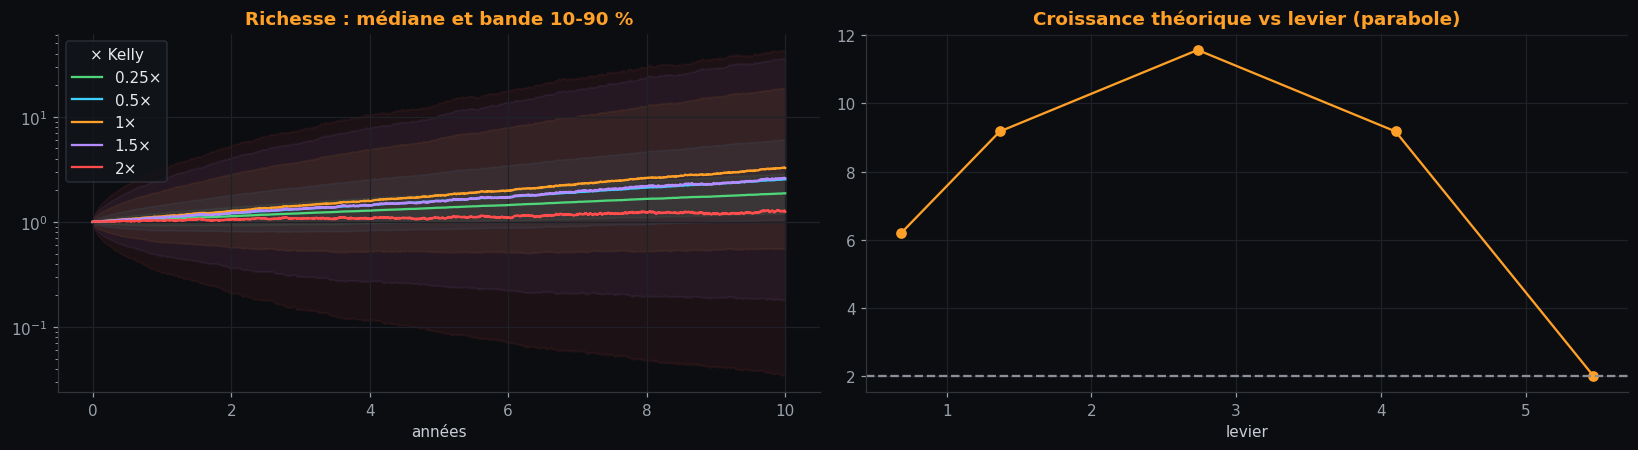

In [7]:
# Distribution de la richesse selon la fraction : queues épaisses (Student t, 5 ddl), r = 2 %
summ, paths = K.simulate_fractional_kelly(0.09, 0.16, 0.02, (0.25, 0.5, 1.0, 1.5, 2.0), years=10, n_paths=5000, dist="t", seed=2)
display(summ)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2)); t = np.arange(paths["1×"].shape[1])/252
for (k, W), col in zip(paths.items(), [GREEN, CYAN, AMBER, VIOLET, RED]):
    ax[0].plot(t, np.median(W, axis=0), color=col, label=k); ax[0].fill_between(t, np.percentile(W, 10, axis=0), np.percentile(W, 90, axis=0), color=col, alpha=.07)
ax[0].set_yscale("log"); ax[0].legend(title="× Kelly"); ax[0].set_title("Richesse : médiane et bande 10-90 %"); ax[0].set_xlabel("années")
ax[1].plot(summ["levier"], summ["g_théorique"]*100, "o-", color=AMBER); ax[1].axhline(2, color=GREY, ls="--")
ax[1].set_title("Croissance théorique vs levier (parabole)"); ax[1].set_xlabel("levier"); plt.tight_layout(); plt.show()

**Lecture** : passer de Kelly plein à ½ Kelly divise fortement la profondeur des drawdowns et la probabilité de perte tout en conservant l'essentiel de la croissance (≈ ¾ du surplus $\tfrac12SR^2$) ; au-delà de $2f^*$ la croissance espérée est inférieure au taux sans risque **malgré un rendement espéré supérieur** — c'est le résultat classique de sur-pari, et l'explication de l'observation d'origine (« avec un levier ×5 on perd de l'argent »).

## 4. Erreur d'estimation : le vrai problème

En pratique $\mu$ et $\sigma$ sont **estimés**. L'erreur sur $\mu$ est énorme (écart-type $\sigma/\sqrt Y$ après $Y$ années : 5 % pour $Y=10$ à 16 % de vol, à comparer à une prime de risque de 4-6 %), alors que $f^*\propto\mu$. Le Kelly « plug-in » est donc un estimateur **bruité et biaisé à la hausse en valeur absolue** : on sur-parie dans les bons échantillons, on sous-parie ailleurs, et l'asymétrie de $g$ (la parabole) pénalise davantage le sur-pari.

Point clé : $g(f)=r+f(\mu-r)-\tfrac12f^2\sigma^2$ est **linéaire en $\mu$**, donc l'allocation qui maximise $E_\mu[\ln W]$ utilise la **moyenne postérieure** de $\mu$ (pas de terme de variance supplémentaire). Le coût vient de la *dispersion* de $\hat f=(\hat\mu-r)/\sigma^2$ autour de $f^*$ : perte moyenne $=\tfrac12\sigma^2\mathrm{Var}(\hat f)=\dfrac1{2Y}$ par an pour le plug-in non tronqué (colonne « oracle − 1/(2Y) » ci-dessous). Remède bayésien : prior $N(0,\tau^2)$ sur le **Sharpe annuel** (τ ≈ 0,4 : un Sharpe supérieur à 1 est très rare) ⇒ $\hat\mu$ rétréci vers 0, puis $f=E[\mu-r]/\sigma^2$.

In [8]:
mu_t, r_t, sig_t = 0.075, 0.02, 0.16        # vrais paramètres
print("Sharpe vrai =", round((mu_t - r_t)/sig_t, 2), "| f* vrai =", round((mu_t - r_t)/sig_t**2, 2))
rng = np.random.default_rng(5)
f_star_t = (mu_t - r_t)/sig_t**2
def g_true(f): return r_t + f*(mu_t - r_t) - .5*f**2*sig_t**2               # croissance RÉELLE obtenue avec l'allocation f
rows = {}
for Y in (3, 5, 10, 20, 40):
    n_obs, M = Y*252, 4000
    mu_hat = mu_t + sig_t/np.sqrt(Y)*rng.standard_normal(M)                  # μ̂ ~ N(μ, σ²/Y)
    f_plug = (mu_hat - r_t)/sig_t**2
    ex_d, sd_d = (mu_hat - r_t)/252, sig_t/np.sqrt(252)
    f_bayes = np.array([K.bayes_shrink_mu(e, sd_d, n_obs, 0.4)[0] for e in ex_d])*252/sig_t**2
    lo = lambda f: np.clip(f, 0, 10)                                         # long-only, levier ≤ 10
    row = {"plug-in (long-only)": g_true(lo(f_plug)).mean(), "½ plug-in": g_true(lo(.5*f_plug)).mean(),
           "Bayes τ=0,4": g_true(lo(f_bayes)).mean(), "½ Bayes": g_true(lo(.5*f_bayes)).mean(),
           "plug-in (short autorisé)": g_true(f_plug).mean(), "oracle − 1/(2Y)": g_true(f_star_t) - 1/(2*Y), "oracle f*": g_true(f_star_t)}
    row["P(g<r) plug-in"] = (g_true(lo(f_plug)) < r_t).mean(); row["P(g<r) Bayes"] = (g_true(lo(f_bayes)) < r_t).mean()
    rows[f"Y = {Y} ans"] = row
est = pd.DataFrame(rows).T
display(est.drop(columns=["P(g<r) plug-in", "P(g<r) Bayes"]).mul(100).round(2).rename_axis("croissance RÉELLE espérée, %/an"))
display(est[["P(g<r) plug-in", "P(g<r) Bayes"]].mul(100).round(1).rename_axis("% d'échantillons où la croissance réelle < taux sans risque"))

Sharpe vrai = 0.34 | f* vrai = 2.15


,plug-in (long-only),½ plug-in,"Bayes τ=0,4",½ Bayes,plug-in (short autorisé),oracle − 1/(2Y),oracle f*
"croissance RÉELLE espérée, %/an",,,,,,,
Y = 3 ans,-2.2800,4.7400,4.9400,4.0100,-8.7500,-8.7600,7.9100
Y = 5 ans,0.9400,5.2100,5.2200,4.3600,-2.3400,-2.0900,7.9100
Y = 10 ans,3.8900,5.6300,5.7100,4.8700,2.7700,2.9100,7.9100
Y = 20 ans,5.6200,5.9000,6.2800,5.3500,5.3900,5.4100,7.9100
Y = 40 ans,6.6700,6.1600,6.8900,5.8200,6.6400,6.6600,7.9100


,P(g<r) plug-in,P(g<r) Bayes
% d'échantillons où la croissance réelle < taux sans risque,,
Y = 3 ans,29.0000,0.1000
Y = 5 ans,23.3000,0.5000
Y = 10 ans,15.3000,0.8000
Y = 20 ans,6.2000,0.6000
Y = 40 ans,1.6000,0.2000


**Ce que montre l'expérience** : (i) la colonne « plug-in (short autorisé) » reproduit la perte théorique $1/(2Y)$ : c'est la vérification de la formule ; (ii) avec peu d'historique, le plug-in est dominé par ½ Kelly et par le rétrécissement bayésien, et une part importante d'échantillons fait *pire que le taux sans risque* ; (iii) l'avantage de la fraction s'estompe quand $Y$ grandit (en espérance), mais la **contrainte de drawdown** (§3) reste, elle, indépendante de $Y$. C'est la justification quantitative du « fractional Kelly » : une **correction d'un biais d'estimation**, pas de l'aversion au risque déguisée. (L'incertitude sur σ est négligée : elle est bien plus faible que celle sur μ.)

## 5. Backtest mono-actif : S&P 500

Poids$_t$ calculés avec l'information $\le t$, appliqués au rendement de $t+1$ (**aucun look-ahead**). On reproduit d'abord le protocole d'origine (moyenne/variance *expanding*, plafonds de levier 1 à 5, sans frictions) puis on ajoute **coûts, financement du levier, shrinkage et Kelly fractionnaire**.

,CAGR,Vol,Sharpe,MaxDD,Calmar,Richesse_finale
plafond ×1,0.0451,0.1458,0.2381,-0.4465,0.1009,3.1551
plafond ×2,0.0465,0.1932,0.2282,-0.5582,0.0832,3.2668
plafond ×3,0.0440,0.1958,0.2160,-0.5823,0.0756,3.0753
plafond ×4,0.0440,0.1958,0.2160,-0.5823,0.0756,3.0753
plafond ×5,0.0440,0.1958,0.2160,-0.5823,0.0756,3.0753
Buy & hold,0.0833,0.2045,0.3956,-0.5491,0.1517,8.0468


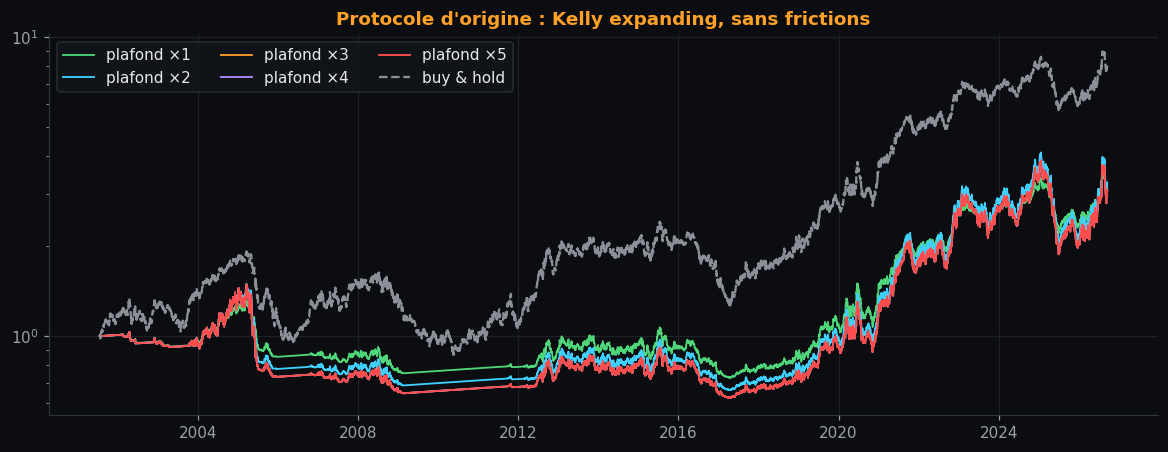

In [9]:
orig = {}
for L in range(1, 6):
    orig[f"plafond ×{L}"] = K.backtest_kelly(r_sp, rf_ann=RF_ANN, est="expanding", min_periods=400, rebalance=1, tau=None, fraction=1.0,
                                             max_leverage=L, long_only=True, cost_bps=0, borrow_spread_ann=0)
bh = K.perf_stats(r_sp.loc[orig["plafond ×1"]["ret"].index], RF_ANN)
tab = pd.DataFrame({k: v["stats"] for k, v in orig.items()}).T
tab.loc["Buy & hold"] = bh
display(tab[["CAGR", "Vol", "Sharpe", "MaxDD", "Calmar", "Richesse_finale"]])
fig, ax = plt.subplots(figsize=(13, 4.5))
for (k, v), col in zip(orig.items(), [GREEN, CYAN, AMBER, VIOLET, RED]):
    ax.plot((1 + v["ret"]).cumprod(), color=col, lw=1.2, label=k)
ax.plot((1 + r_sp.loc[orig["plafond ×1"]["ret"].index]).cumprod(), color=GREY, ls="--", label="buy & hold"); ax.set_yscale("log"); ax.legend(ncol=3); ax.set_title("Protocole d'origine : Kelly expanding, sans frictions"); plt.show()

,CAGR,Vol,Sharpe,MaxDD,Calmar,Turnover/an,Levier moyen
"expanding, plein Kelly, plug-in",0.0410,0.1975,0.2011,-0.5916,0.0693,2.1091,0.8056
"expanding, ½ Kelly, plug-in",0.0361,0.0987,0.2059,-0.3103,0.1163,1.0546,0.4028
"expanding, ½ Kelly, shrinkage τ=0,4",0.0370,0.0711,0.2656,-0.2454,0.1508,0.6026,0.2832
"rolling 3 ans, ½ Kelly, shrinkage",0.0392,0.1007,0.2331,-0.2279,0.1718,1.3643,0.3499
"EWMA (hl 1 an), ½ Kelly, shrinkage",0.0338,0.0771,0.2105,-0.1447,0.2337,1.7632,0.2839
"expanding, ¼ Kelly, shrinkage",0.0292,0.0355,0.2656,-0.1264,0.2312,0.3013,0.1416
Buy & hold,0.0808,0.2051,0.3839,-0.5491,0.1471,0.0000,1.0000


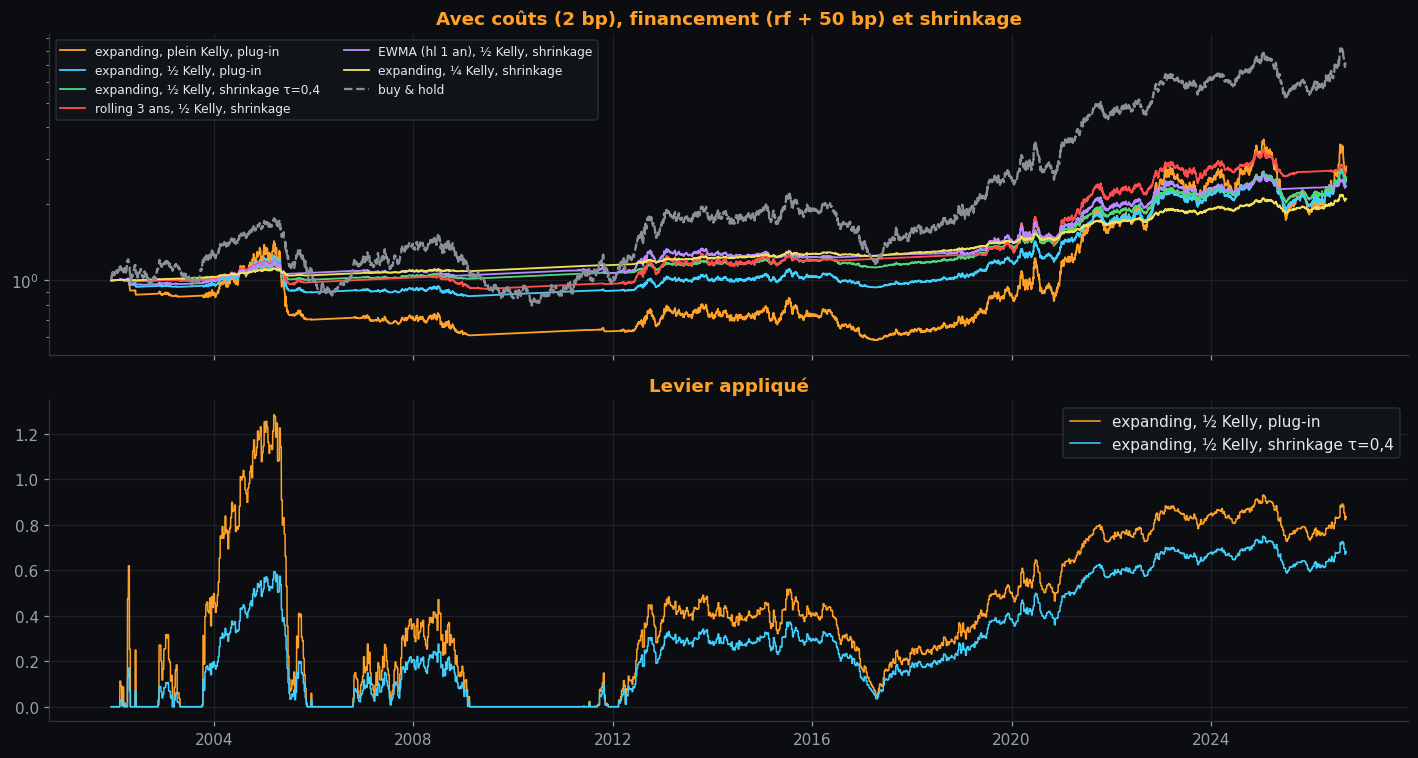

In [10]:
cfgs = {
    "expanding, plein Kelly, plug-in":      dict(est="expanding", tau=None, fraction=1.0, max_leverage=3),
    "expanding, ½ Kelly, plug-in":          dict(est="expanding", tau=None, fraction=0.5, max_leverage=3),
    "expanding, ½ Kelly, shrinkage τ=0,4":  dict(est="expanding", tau=0.4, fraction=0.5, max_leverage=3),
    "rolling 3 ans, ½ Kelly, shrinkage":    dict(est="rolling", window=756, tau=0.4, fraction=0.5, max_leverage=3),
    "EWMA (hl 1 an), ½ Kelly, shrinkage":   dict(est="ewma", halflife=252, tau=0.4, fraction=0.5, max_leverage=3),
    "expanding, ¼ Kelly, shrinkage":        dict(est="expanding", tau=0.4, fraction=0.25, max_leverage=3),
}
real = {k: K.backtest_kelly(r_sp, rf_ann=RF_ANN, min_periods=504, rebalance=5, cost_bps=2.0, borrow_spread_ann=0.005, **v) for k, v in cfgs.items()}
tab = pd.DataFrame({k: {**v["stats"], "Turnover/an": v["turnover_ann"], "Levier moyen": v["leverage"].mean()} for k, v in real.items()}).T
idx0 = real["expanding, ½ Kelly, plug-in"]["ret"].index
tab.loc["Buy & hold"] = {**K.perf_stats(r_sp.loc[idx0], RF_ANN), "Turnover/an": 0.0, "Levier moyen": 1.0}
display(tab[["CAGR", "Vol", "Sharpe", "MaxDD", "Calmar", "Turnover/an", "Levier moyen"]])
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for k, v in real.items(): ax[0].plot((1 + v["ret"]).cumprod(), lw=1.2, label=k)
ax[0].plot((1 + r_sp.loc[idx0]).cumprod(), color=GREY, ls="--", label="buy & hold"); ax[0].set_yscale("log"); ax[0].legend(fontsize=8, ncol=2); ax[0].set_title("Avec coûts (2 bp), financement (rf + 50 bp) et shrinkage")
for k in ("expanding, ½ Kelly, plug-in", "expanding, ½ Kelly, shrinkage τ=0,4"): ax[1].plot(real[k]["leverage"], lw=1, label=k)
ax[1].set_title("Levier appliqué"); ax[1].legend(); plt.tight_layout(); plt.show()

**À vérifier dans ces résultats** : (i) le levier du plug-in est instable (il suit le bruit de $\hat\mu$) → turnover et drawdowns plus élevés ; (ii) le shrinkage et la fraction réduisent le levier moyen et le turnover ; (iii) la sensibilité aux **plafonds** doit être lue à la lumière de la section 3 : un plafond de levier est un *substitut grossier* de fraction de Kelly ; (iv) un Sharpe de backtest sur un seul actif et une seule trajectoire est **une seule réalisation** — ne pas le sur-interpréter.

## 6. Portefeuille de 15 actions

**Kelly contraint** : on résout $\max_F\ r+F^\top(M-r)-\tfrac12F^\top\Sigma F$ sous $\sum_i|F_i|\le L$ (et $F\ge0$ si long-only), avec **covariance de Ledoit-Wolf** (rétrécie), puis on applique la fraction. Ceci **remplace** la normalisation $f^{**}_i=\alpha f^*_i/\sum f^*_i$ de la version d'origine, qui ne résout pas le problème contraint (elle change la direction du portefeuille et diverge quand $\sum f^*_i\to0$).

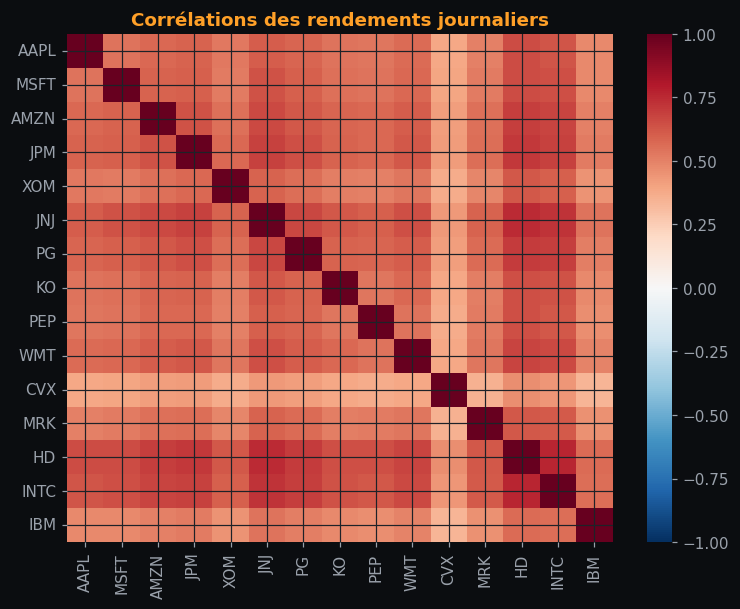

Conditionnement de la covariance — historique complet : échantillon = 36, Ledoit-Wolf = 36 | 250 derniers jours : échantillon = 46, Ledoit-Wolf = 40


,F* non contraint (cov. échantillon),F* non contraint (Ledoit-Wolf),"long-only, Σ|F| ≤ 1 (LW)"
AAPL,1.0402,1.0395,0.0000
MSFT,-2.3097,-2.3049,0.0000
AMZN,-0.1685,-0.1673,0.0000
JPM,3.6630,3.6499,0.4667
XOM,3.1563,3.1500,0.5333
JNJ,0.9086,0.9070,0.0000
PG,0.9361,0.9354,0.0000
KO,0.4189,0.4185,0.0000
PEP,0.0149,0.0149,0.0000
WMT,-1.1454,-1.1417,0.0000


In [11]:
plt.figure(figsize=(8, 6)); sns.heatmap(R_stk.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=False); plt.title("Corrélations des rendements journaliers"); plt.show()
mu_h, C_h = R_stk.mean().values, R_stk.cov().values
F_unc = K.kelly_multi(mu_h, C_h, rf_d)
F_lw = K.kelly_multi(mu_h, K.shrunk_covariance(R_stk, "lw"), rf_d)
F_con = K.kelly_constrained(mu_h, K.shrunk_covariance(R_stk, "lw"), rf_d, 1.0, True, 1.0)
alloc = pd.DataFrame({"F* non contraint (cov. échantillon)": F_unc, "F* non contraint (Ledoit-Wolf)": F_lw, "long-only, Σ|F| ≤ 1 (LW)": F_con}, index=R_stk.columns)
alloc.loc["Σ|F|"] = alloc.abs().sum()
short = R_stk.iloc[-250:]
print(f"Conditionnement de la covariance — historique complet : échantillon = {np.linalg.cond(C_h):.0f}, Ledoit-Wolf = {np.linalg.cond(K.shrunk_covariance(R_stk, 'lw')):.0f}"
      f" | 250 derniers jours : échantillon = {np.linalg.cond(short.cov().values):.0f}, Ledoit-Wolf = {np.linalg.cond(K.shrunk_covariance(short, 'lw')):.0f}")
display(alloc)

,CAGR,Vol,Sharpe,MaxDD,Calmar,Turnover/an,Levier moyen
"Kelly LW, long-only, L=1, ½",0.0498,0.0807,0.3944,-0.1990,0.2501,0.9502,0.4939
"Kelly LW, long-only, L=2, ½",0.0769,0.1436,0.4485,-0.3293,0.2336,1.5537,0.9292
"Kelly LW, long/short, L=2, ½",0.0455,0.1312,0.2524,-0.3273,0.1391,2.0644,0.6633
"Kelly décorrélé (diag), L=2, ½",0.0755,0.1524,0.4223,-0.4221,0.1788,1.6137,0.9808
Équipondéré (quotidien),0.0948,0.1546,0.5338,-0.4965,0.1909,NaN,1.0000
Inverse-vol 60 j,0.0939,0.1506,0.5383,-0.4795,0.1958,NaN,1.0000


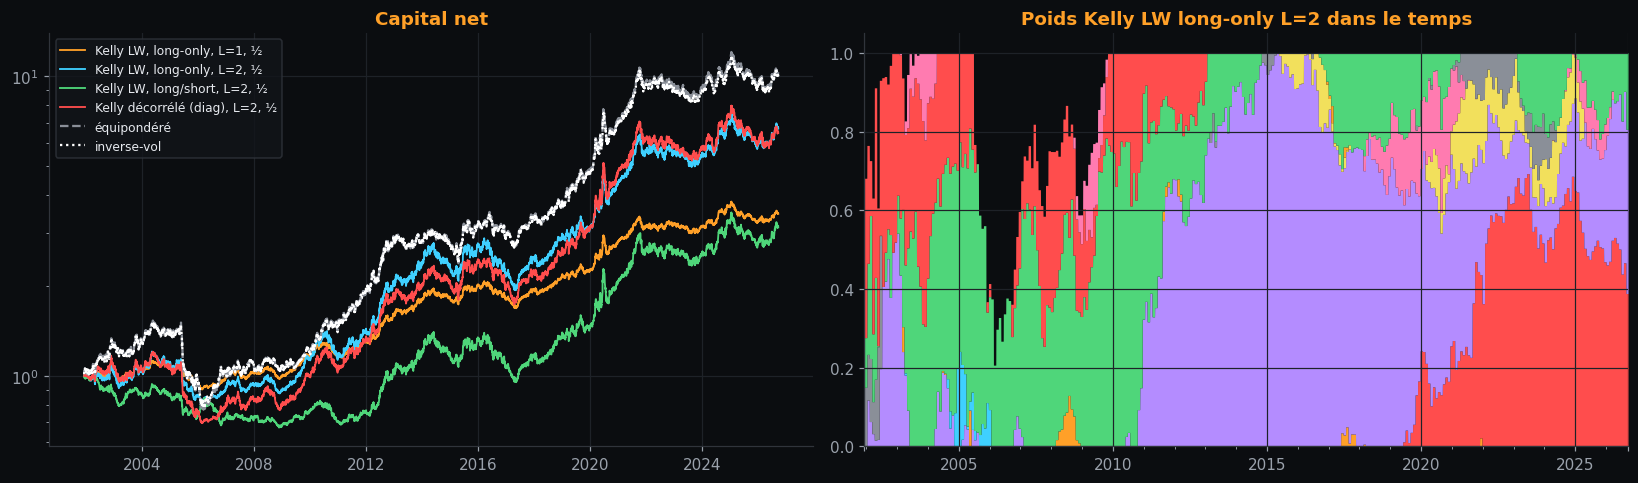

In [12]:
common = dict(rf_ann=RF_ANN, min_periods=504, rebalance=21, cost_bps=2.0, borrow_spread_ann=0.005, short_fee_ann=0.003, est="expanding", tau=0.4)
runs = {
    "Kelly LW, long-only, L=1, ½":      K.backtest_kelly(R_stk, cov="lw",   max_leverage=1, long_only=True,  fraction=0.5, **{k: v for k, v in common.items()}),
    "Kelly LW, long-only, L=2, ½":      K.backtest_kelly(R_stk, cov="lw",   max_leverage=2, long_only=True,  fraction=0.5, **common),
    "Kelly LW, long/short, L=2, ½":     K.backtest_kelly(R_stk, cov="lw",   max_leverage=2, long_only=False, fraction=0.5, **common),
    "Kelly décorrélé (diag), L=2, ½":   K.backtest_kelly(R_stk, cov="diag", max_leverage=2, long_only=True,  fraction=0.5, **common),
}
first = min(v["ret"].index[0] for v in runs.values())
ew = R_stk.mean(axis=1).loc[first:]                                                       # équipondéré rebalancé chaque jour
iv = (R_stk / R_stk.rolling(60).std().shift(1)).div((1 / R_stk.rolling(60).std().shift(1)).sum(axis=1), axis=0).mul(1)  # inverse-vol (approx.)
w_iv = (1 / R_stk.rolling(60).std()).div((1 / R_stk.rolling(60).std()).sum(axis=1), axis=0).shift(1)
iv_ret = (w_iv * R_stk).sum(axis=1).loc[first:]
tab = pd.DataFrame({k: {**v["stats"], "Turnover/an": v["turnover_ann"], "Levier moyen": v["leverage"].mean()} for k, v in runs.items()}).T
tab.loc["Équipondéré (quotidien)"] = {**K.perf_stats(ew, RF_ANN), "Turnover/an": np.nan, "Levier moyen": 1.0}
tab.loc["Inverse-vol 60 j"] = {**K.perf_stats(iv_ret, RF_ANN), "Turnover/an": np.nan, "Levier moyen": 1.0}
display(tab[["CAGR", "Vol", "Sharpe", "MaxDD", "Calmar", "Turnover/an", "Levier moyen"]])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for k, v in runs.items(): ax[0].plot((1 + v["ret"]).cumprod(), lw=1.2, label=k)
ax[0].plot((1 + ew).cumprod(), color=GREY, ls="--", label="équipondéré"); ax[0].plot((1 + iv_ret).cumprod(), color="white", ls=":", label="inverse-vol"); ax[0].set_yscale("log"); ax[0].legend(fontsize=8); ax[0].set_title("Capital net")
runs["Kelly LW, long-only, L=2, ½"]["weights"].plot.area(ax=ax[1], legend=False, lw=0); ax[1].set_title("Poids Kelly LW long-only L=2 dans le temps"); plt.tight_layout(); plt.show()

**Corrélé vs décorrélé** : ignorer les corrélations (matrice diagonale) surestime le bénéfice de diversification et concentre le risque sur les actifs à fort $\hat\mu/\hat\sigma^2$ ; la covariance rétrécie est le compromis standard (avec $T\gg N$ l'effet est faible, il devient déterminant quand le ratio $T/N$ est petit — fenêtres de 1 à 3 ans, comme dans les backtests glissants). Comparer aussi aux benchmarks naïfs : *battre l'équipondéré net de coûts* est le vrai test.

## 7. Kelly contre vol-targeting, règles de desk, export

In [13]:
vol_ewma = np.sqrt((r_sp**2).ewm(alpha=.06).mean()*252)
w_vt = (0.10/vol_ewma).clip(upper=3).shift(1)
vt = (w_vt*r_sp + (1 - w_vt)*rf_d - (w_vt-1).clip(lower=0)*.005/252).loc[idx0]
kf = real["expanding, ½ Kelly, shrinkage τ=0,4"]["ret"]
cmp_ = pd.DataFrame({"Vol-target 10 %": K.perf_stats(vt, RF_ANN), "½ Kelly + shrinkage": K.perf_stats(kf, RF_ANN), "Buy & hold": K.perf_stats(r_sp.loc[idx0], RF_ANN)}).T
display(cmp_[["CAGR", "Vol", "Sharpe", "MaxDD", "Calmar"]])

,CAGR,Vol,Sharpe,MaxDD,Calmar
Vol-target 10 %,0.0640,0.1039,0.4564,-0.2768,0.2312
½ Kelly + shrinkage,0.0370,0.0711,0.2656,-0.2454,0.1508
Buy & hold,0.0808,0.2051,0.3839,-0.5491,0.1471


**Kelly vs vol-targeting** : le vol-targeting ne dépend pas de $\hat\mu$ (bruité) mais seulement de $\hat\sigma$ (bien estimé et persistant) ; Kelly fractionnaire y ajoute une vue sur le rendement. Un compromis courant : *vol-target de base + tilt Kelly plafonné*.

### Règles de desk (checklist)
1. **Jamais Kelly plein** : ¼ à ½ Kelly, justifié par l'erreur d'estimation *et* le drawdown (§3-4).
2. **Contrainte de drawdown → fraction** : $c=2/(1+\ln\beta/\ln x)$.
3. **Estimer avec rétrécissement** (μ vers 0/prior, Σ Ledoit-Wolf) et fenêtres explicites ; jamais de moyenne sur l'échantillon complet dans un backtest.
4. **Plafonner** levier brut et net ; tenir compte du financement (rf + spread) et des coûts sur le turnover ; rebalancer avec une bande de tolérance pour limiter le turnover.
5. **Kelly empirique** pour comparer avec la version gaussienne quand les queues sont épaisses.
6. **Réévaluer** après régime (ruptures de vol/corrélation) : la stationnarité est une hypothèse, pas un fait.

In [14]:
W = K.kelly_signal(R_stk, rf_ann=RF_ANN, est="expanding", min_periods=504, rebalance=21, cov="lw", tau=0.4, max_leverage=2, long_only=True, fraction=0.5).iloc[-1]
sp_f = K.kelly_signal(r_sp, rf_ann=RF_ANN, est="expanding", min_periods=504, rebalance=5, tau=0.4, max_leverage=3, long_only=True, fraction=0.5).iloc[-1, 0]
snap = {"meta": {"as_of": str(R_stk.index[-1].date()), "source": SOURCE, "rf_annual": RF_ANN, "fraction": 0.5, "max_leverage": 2, "shrinkage_tau": 0.4},
        "single_asset_sp500": {"kelly_fraction_applied": float(sp_f), "gaussian_full_kelly": float(f_gauss), "empirical_full_kelly": float(f_emp)},
        "portfolio_weights": {k: float(v) for k, v in W.items()}, "cash_weight": float(1 - W.sum()),
        "drawdown_table": {f"P(touch {int(x*100)}%)@c={c}": K.prob_drawdown(c, x) for x in (0.7, 0.5) for c in (0.5, 1.0)}}
with open("kelly_snapshot.json", "w") as fh: json.dump(snap, fh, indent=2)
display(W.to_frame("poids cible").T.round(3)); print("cash :", round(1 - W.sum(), 3), "| kelly_snapshot.json écrit")

,AAPL,MSFT,AMZN,JPM,XOM,JNJ,PG,KO,PEP,WMT,CVX,MRK,HD,INTC,IBM
poids cible,0.0000,0.0000,0.0000,0.3880,0.4170,0.0000,0.0000,0.0000,0.0000,0.0000,0.1950,0.0000,0.0000,0.0000,0.0000


cash : -0.0 | kelly_snapshot.json écrit


## 8. Ce qui a été corrigé par rapport à la version d'origine

| # | Problème dans le notebook d'origine | Correction |
|---|---|---|
| 1 | $g(f)$ écrit avec **$+\tfrac12f^2s^2$** : la fonction serait convexe, sans maximum ; $f^*=(m-r)/s^2$ n'en découlerait pas | Signe **moins** (parabole concave), dérivation refaite proprement |
| 2 | Développement de $\ln(1+z)$ avec mauvais signes (« $+\frac{z^3}3+\dots+\frac{z^n}n$ ») et termes $U_s/n$ dimensionnellement faux (le choc est en $\sigma U/\sqrt n$) | Série alternée, ordres en $n$ corrigés |
| 3 | « $f_0+\dots+f_n=1$ » puis $F^*=C^{-1}(M-R)$ : contradictoire (les poids risqués ne somment pas à 1, le solde est du cash) | Distinction poids risqués / cash |
| 4 | Plafond de levier par $f^{**}_i=\alpha f^*_i/\sum f^*_i$ | Optimisation sous contrainte $\sum|F_i|\le L$ (+ long-only) |
| 5 | Moyenne/variance *expanding* brutes, aucun traitement de l'incertitude : « des Kelly plus grands n'impliquent pas de rendements plus grands » attribué au hasard | Analyse d'erreur d'estimation, shrinkage bayésien, fractions |
| 6 | Hypothèse « monde parfait » (pas de coûts, ni de financement, ni de taxes) | Coûts, spread de financement, frais de short |
| 7 | Bernoulli 1713 « qui découvrit plus tard la solution » | Nicolas Bernoulli pose le problème (1713) ; c'est **Daniel Bernoulli** qui propose la solution par l'utilité logarithmique (1738) |
| 8 | `utils.py`, `sp500.csv`, `stocks.csv` absents ⇒ notebook non exécutable ; 5,8 Mo de sorties embarquées | Module `quantdesk` (avec couche de compatibilité `quantdesk.utils`), chargement réel/synthétique, sorties allégées |
| 9 | Pas de lien avec le risque de ruine ni de drawdown | Formule exacte de probabilité de drawdown et vérification Monte-Carlo |

**Limites** : Kelly suppose des rendements i.i.d. de paramètres connus et un rebalancement continu ; les vrais marchés ont des sauts, des régimes et de l'illiquidité. Le Kelly d'un portefeuille avec dérivés non linéaires exige une optimisation sur la distribution complète des P&L (Kelly empirique multi-actifs) plutôt que sur $(\mu,\Sigma)$.